# 1. Data Loading & Preprocessing

- Load 8 Parquet
- Kiểm tra dataset
- Gộp dữ liệu
- AttackType
- BinaryLabel
- xử lý NaN/Inf
- duplicate
- chọn numerical features
- lưu dataset đã xử lý

In [1]:
import os
import glob
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("Libraries imported successfully.")

Libraries imported successfully.


# Dataset path

In [2]:
DATA_DIR = "../Dataset Full"

files = sorted(glob.glob(os.path.join(DATA_DIR, "*.parquet")))

print("Number of dataset files:", len(files))

for f in files:
    print(os.path.basename(f))

Number of dataset files: 8
Benign-Monday-no-metadata.parquet
Botnet-Friday-no-metadata.parquet
Bruteforce-Tuesday-no-metadata.parquet
DDoS-Friday-no-metadata.parquet
DoS-Wednesday-no-metadata.parquet
Infiltration-Thursday-no-metadata.parquet
Portscan-Friday-no-metadata.parquet
WebAttacks-Thursday-no-metadata.parquet


# Kiểm tra dataset

In [3]:
assert len(files) == 8, "Expected 8 Parquet files."

for f in files:
    size_mb = os.path.getsize(f) / (1024 * 1024)
    print(f"{os.path.basename(f):50s} {size_mb:.2f} MB")

Benign-Monday-no-metadata.parquet                  54.14 MB
Botnet-Friday-no-metadata.parquet                  18.94 MB
Bruteforce-Tuesday-no-metadata.parquet             44.00 MB
DDoS-Friday-no-metadata.parquet                    24.13 MB
DoS-Wednesday-no-metadata.parquet                  65.04 MB
Infiltration-Thursday-no-metadata.parquet          22.07 MB
Portscan-Friday-no-metadata.parquet                12.96 MB
WebAttacks-Thursday-no-metadata.parquet            16.84 MB


# Đọc dữ liệu

In [4]:
import glob
import os
import pandas as pd

path = r"D:\ANM\Topic 30\Dataset Full" 
files = glob.glob(os.path.join(path, "*.parquet"))

dataframes = []

for file in files:
    print("Reading:", os.path.basename(file))

    temp = pd.read_parquet(file)

    # Store source file
    temp["SourceFile"] = os.path.basename(file)

    dataframes.append(temp)

df_all = pd.concat(dataframes, ignore_index=True)

print("\nFinal shape:", df_all.shape)

Reading: Benign-Monday-no-metadata.parquet
Reading: Botnet-Friday-no-metadata.parquet
Reading: Bruteforce-Tuesday-no-metadata.parquet
Reading: DDoS-Friday-no-metadata.parquet
Reading: DoS-Wednesday-no-metadata.parquet
Reading: Infiltration-Thursday-no-metadata.parquet
Reading: Portscan-Friday-no-metadata.parquet
Reading: WebAttacks-Thursday-no-metadata.parquet

Final shape: (2313810, 79)


# Kiểm tra dữ liệu

In [5]:
print("Rows:", df_all.shape[0])
print("Columns:", df_all.shape[1])

display(df_all.head())

Rows: 2313810
Columns: 79


,Protocol,Flow Duration,Total Fwd Packets,Total Backward Packets,Fwd Packets Length Total,Bwd Packets Length Total,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Max,Bwd Packet Length Min,Bwd Packet Length Mean,Bwd Packet Length Std,Flow Bytes/s,Flow Packets/s,Flow IAT Mean,Flow IAT Std,Flow IAT Max,Flow IAT Min,Fwd IAT Total,Fwd IAT Mean,Fwd IAT Std,Fwd IAT Max,Fwd IAT Min,Bwd IAT Total,Bwd IAT Mean,Bwd IAT Std,Bwd IAT Max,Bwd IAT Min,Fwd PSH Flags,Bwd PSH Flags,Fwd URG Flags,Bwd URG Flags,Fwd Header Length,Bwd Header Length,Fwd Packets/s,Bwd Packets/s,Packet Length Min,Packet Length Max,Packet Length Mean,Packet Length Std,Packet Length Variance,FIN Flag Count,SYN Flag Count,RST Flag Count,PSH Flag Count,ACK Flag Count,URG Flag Count,CWE Flag Count,ECE Flag Count,Down/Up Ratio,Avg Packet Size,Avg Fwd Segment Size,Avg Bwd Segment Size,Fwd Avg Bytes/Bulk,Fwd Avg Packets/Bulk,Fwd Avg Bulk Rate,Bwd Avg Bytes/Bulk,Bwd Avg Packets/Bulk,Bwd Avg Bulk Rate,Subflow Fwd Packets,Subflow Fwd Bytes,Subflow Bwd Packets,Subflow Bwd Bytes,Init Fwd Win Bytes,Init Bwd Win Bytes,Fwd Act Data Packets,Fwd Seg Size Min,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label,SourceFile
0,6,4,2,0,12,0,6,6,6.00000,0.000000,0,0,0.0,0.000000,3.000000e+06,5.000000e+05,4.000000,0.000000,4,4,4,4.0,0.000000,4,4,0,0.000000,0.000000,0,0,0,0,0,0,40,0,5.000000e+05,0.000000,6,6,6.000000,0.000000,0.000000,0,0,0,0,1,1,0,0,0,9.00000,6.00000,0.0,0,0,0,0,0,0,2,12,0,0,329,-1,1,20,0.0,0.0,0,0,0.0,0.0,0,0,Benign,Benign-Monday-no-metadata.parquet
1,6,1,2,0,12,0,6,6,6.00000,0.000000,0,0,0.0,0.000000,1.200000e+07,2.000000e+06,1.000000,0.000000,1,1,1,1.0,0.000000,1,1,0,0.000000,0.000000,0,0,0,0,0,0,40,0,2.000000e+06,0.000000,6,6,6.000000,0.000000,0.000000,0,0,0,0,1,1,0,0,0,9.00000,6.00000,0.0,0,0,0,0,0,0,2,12,0,0,329,-1,1,20,0.0,0.0,0,0,0.0,0.0,0,0,Benign,Benign-Monday-no-metadata.parquet
2,6,3,2,0,12,0,6,6,6.00000,0.000000,0,0,0.0,0.000000,4.000000e+06,6.666667e+05,3.000000,0.000000,3,3,3,3.0,0.000000,3,3,0,0.000000,0.000000,0,0,0,0,0,0,40,0,6.666667e+05,0.000000,6,6,6.000000,0.000000,0.000000,0,0,0,0,1,1,0,0,0,9.00000,6.00000,0.0,0,0,0,0,0,0,2,12,0,0,245,-1,1,20,0.0,0.0,0,0,0.0,0.0,0,0,Benign,Benign-Monday-no-metadata.parquet
3,6,1,2,0,12,0,6,6,6.00000,0.000000,0,0,0.0,0.000000,1.200000e+07,2.000000e+06,1.000000,0.000000,1,1,1,1.0,0.000000,1,1,0,0.000000,0.000000,0,0,0,0,0,0,40,0,2.000000e+06,0.000000,6,6,6.000000,0.000000,0.000000,0,0,0,0,1,1,0,0,0,9.00000,6.00000,0.0,0,0,0,0,0,0,2,12,0,0,245,-1,1,20,0.0,0.0,0,0,0.0,0.0,0,0,Benign,Benign-Monday-no-metadata.parquet
4,6,609,7,4,484,414,233,0,69.14286,111.967896,207,0,103.5,119.511505,1.474548e+06,1.806240e+04,60.900002,115.194954,381,2,609,101.5,177.089523,460,2,467,155.666672,263.560883,460,3,0,0,0,0,164,104,1.149425e+04,6568.144531,0,233,74.833336,107.527443,11562.151367,0,0,0,1,0,0,0,0,0,81.63636,69.14286,103.5,0,0,0,0,0,0,7,484,4,414,8192,2053,5,20,0.0,0.0,0,0,0.0,0.0,0,0,Benign,Benign-Monday-no-metadata.parquet


# Column names

In [6]:
import math

num_cols = 3     # Số cột màn hình muốn hiển thị song song
col_width = 35   # Độ rộng mỗi cột 

cols = list(enumerate(df_all.columns))
n = len(cols)
num_rows = math.ceil(n / num_cols)

for r in range(num_rows):
    line = ""
    for c in range(num_cols):
        idx = r + c * num_rows
        if idx < n:
            i, col_name = cols[idx]
            item = f"{i:>2}: {col_name}"
            line += f"{item:<{col_width}}"
    print(line)

 0: Protocol                       27: Bwd IAT Std                    54: Avg Bwd Segment Size           
 1: Flow Duration                  28: Bwd IAT Max                    55: Fwd Avg Bytes/Bulk             
 2: Total Fwd Packets              29: Bwd IAT Min                    56: Fwd Avg Packets/Bulk           
 3: Total Backward Packets         30: Fwd PSH Flags                  57: Fwd Avg Bulk Rate              
 4: Fwd Packets Length Total       31: Bwd PSH Flags                  58: Bwd Avg Bytes/Bulk             
 5: Bwd Packets Length Total       32: Fwd URG Flags                  59: Bwd Avg Packets/Bulk           
 6: Fwd Packet Length Max          33: Bwd URG Flags                  60: Bwd Avg Bulk Rate              
 7: Fwd Packet Length Min          34: Fwd Header Length              61: Subflow Fwd Packets            
 8: Fwd Packet Length Mean         35: Bwd Header Length              62: Subflow Fwd Bytes              
 9: Fwd Packet Length Std          36: Fwd Pac

# Label distribution

In [7]:
# Sửa ký tự lạ  (hoặc các khoảng trắng không chuẩn) thành khoảng trắng chuẩn ' '
df_all["Label"] = (
    df_all["Label"]
    .astype(str)
    .str.replace(r"[^\x00-\x7F]+", " ", regex=True)  # Xóa ký tự non-ASCII 
    .str.replace(r"\s+", " ", regex=True)            # Thay nhiều khoảng trắng liền nhau thành 1 khoảng trắng
    .str.strip()                                     # Xóa khoảng trắng thừa ở đầu/cuối
)

# Kiểm tra lại kết quả phân bố nhãn
print(df_all["Label"].value_counts(dropna=False))

Label
Benign                      1977318
DoS Hulk                     172846
DDoS                         128014
DoS GoldenEye                 10286
FTP-Patator                    5931
DoS slowloris                  5385
DoS Slowhttptest               5228
SSH-Patator                    3219
PortScan                       1956
Web Attack Brute Force         1470
Bot                            1437
Web Attack XSS                  652
Infiltration                     36
Web Attack Sql Injection         21
Heartbleed                       11
Name: count, dtype: int64


# Chuẩn hóa tên attack

In [8]:
def detect_attack_type(filename):
    name = filename.lower()

    if "benign" in name:
        return "Benign"
    elif "botnet" in name:
        return "Botnet"
    elif "bruteforce" in name:
        return "Bruteforce"
    elif "ddos" in name:
        return "DDoS"
    elif "dos" in name:
        return "DoS"
    elif "infiltration" in name:
        return "Infiltration"
    elif "portscan" in name:
        return "Portscan"
    elif "webattacks" in name:
        return "WebAttacks"
    else:
        return "Unknown"


df_all["AttackType"] = df_all["SourceFile"].apply(detect_attack_type)

print(df_all["AttackType"].value_counts())

AttackType
DoS             584991
Benign          458831
Bruteforce      389714
DDoS            221264
Infiltration    207630
Botnet          176038
WebAttacks      155820
Portscan        119522
Name: count, dtype: int64


# Binary label

In [9]:
df_all["BinaryLabel"] = (
    df_all["AttackType"]
    .apply(lambda x: 0 if x == "Benign" else 1)
)

print(df_all["BinaryLabel"].value_counts())

print("\n0 = Benign")
print("1 = Attack")

BinaryLabel
1    1854979
0     458831
Name: count, dtype: int64

0 = Benign
1 = Attack


# Missing values

In [10]:
missing = df_all.isnull().sum()

missing = (
    missing[missing > 0]
    .sort_values(ascending=False)
)

print("Columns containing missing values:")
display(missing.head(30))

Columns containing missing values:


Series([], dtype: int64)

# Infinite values

In [11]:
numeric_cols = df_all.select_dtypes(include=np.number).columns

inf_counts = np.isinf(
    df_all[numeric_cols]
).sum()

inf_counts = inf_counts[inf_counts > 0]

print("Columns containing infinite values:")
display(inf_counts.sort_values(ascending=False).head(30))

Columns containing infinite values:


Series([], dtype: int64)

# Cleaning

In [12]:
before_rows = len(df_all)

# Replace infinity
df_all = df_all.replace(
    [np.inf, -np.inf],
    np.nan
)

# Remove duplicated rows
df_all = df_all.drop_duplicates()

# Remove rows with missing values
df_all = df_all.dropna()

after_rows = len(df_all)

print("Rows before cleaning:", before_rows)
print("Rows after cleaning :", after_rows)
print("Rows removed        :", before_rows - after_rows)

Rows before cleaning: 2313810
Rows after cleaning : 2313810
Rows removed        : 0


# Kiểm tra dữ liệu sau cleaning

In [13]:
print("Remaining NaN:", df_all.isna().sum().sum())

numeric_cols = df_all.select_dtypes(include=np.number).columns

print(
    "Remaining Inf:",
    np.isinf(df_all[numeric_cols]).sum().sum()
)

Remaining NaN: 0
Remaining Inf: 0


# Attack distribution

In [14]:
attack_distribution = (
    df_all["AttackType"]
    .value_counts()
    .sort_values(ascending=False)
)

display(attack_distribution)

AttackType
DoS             584991
Benign          458831
Bruteforce      389714
DDoS            221264
Infiltration    207630
Botnet          176038
WebAttacks      155820
Portscan        119522
Name: count, dtype: int64

# Visualization

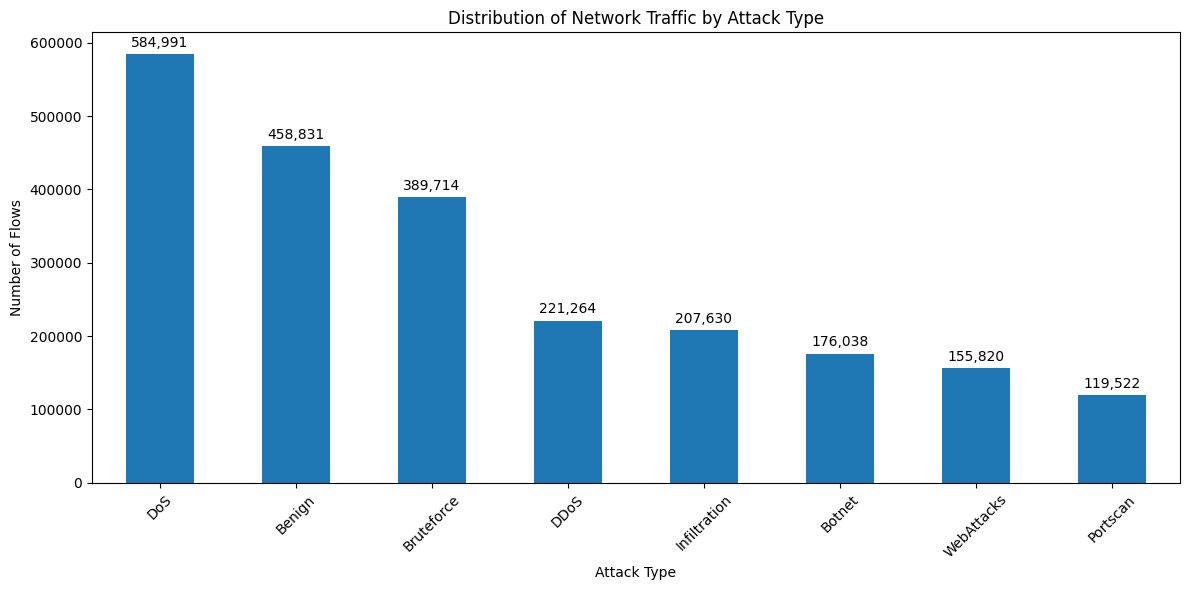

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))

ax = attack_distribution.plot(kind="bar")

# Thêm số cụ thể lên đỉnh từng cột
for p in ax.patches:
    ax.annotate(f"{int(p.get_height()):,}", 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='bottom', xytext=(0, 3), 
                textcoords='offset points')

plt.title("Distribution of Network Traffic by Attack Type")
plt.xlabel("Attack Type")
plt.ylabel("Number of Flows")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

# Lưu dữ liệu sạch

In [16]:
os.makedirs("../Results", exist_ok=True)

df_all.to_parquet(
    "../Results/cleaned_cic_ids2017.parquet",
    index=False
)

print("Cleaned dataset saved.")

Cleaned dataset saved.
